In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from tqdm import tqdm
import warnings
from scipy import stats
from scipy.stats import gaussian_kde
from collections import defaultdict

In [33]:
## Load P-P files
cell_lines = {'Caco-2', 'HCT116', 'HepG2', 'K562', 'MCF-7', 'MCF'}
pp_base_path = '/data/zusers/moorej3/Moore-Lab/Papers/3D-Genome/2_Promoter-Centric/Promoter-Promoter-Pairs'

cell_lines_dfs = {}

for cell in cell_lines:
    cell_lines_dfs[cell] = pd.read_csv(f"{pp_base_path}/{cell}.P-P-Pairs.txt", sep = "\t", header = None)
    cell_lines_dfs[cell].columns = ['P1', 'P2', 'id', 'P1_gene', 'P2_gene']
    cell_lines_dfs[cell]['P1_gene'] = cell_lines_dfs[cell]['P1_gene'].str.split('.').str[0]
    cell_lines_dfs[cell]['P2_gene'] = cell_lines_dfs[cell]['P2_gene'].str.split('.').str[0]

In [34]:
## Load cCRE files
cCRE_ids = {'Caco-2', 'HCT116', 'HepG2', 'K562', 'MCF-7', 'MCF.10A'}
cCRE_base = '/zata/zippy/likhitem/moore_lab_rotation/BENGI/additional_data/cCRE_files'

cCRE_files = {}

for cell in cCRE_ids:
    cCRE_files[cell] = pd.read_csv(f"{cCRE_base}/{cell}-cCREs.bed", sep = "\t", header = None, usecols = [0,1,2,3,9])
    cCRE_files[cell].columns = ['chr','start','end','P','function']
    cCRE_files[cell] = cCRE_files[cell][cCRE_files[cell]['function'] == 'PLS'].reset_index(drop=True)
    cCRE_files[cell] = cCRE_files[cell].drop(columns = 'function')

In [35]:
## Change up cCRE MCF-10A name so it'll match
cCRE_files['MCF'] = cCRE_files.pop('MCF.10A')

In [36]:
## Load Bru-seq files (Check M. Ljungman file to determine columns)
bru_files = {
        "MCF-7":       "/data/projects/encode/data/ENCSR727IHV/ENCFF427SAT.tsv",
        "Caco-2":      "/data/projects/encode/data/ENCSR892NYB/ENCFF147PXW.tsv",
        "HCT116":     "/data/projects/encode/data/ENCSR799MPW/ENCFF976WNX.tsv",
        "HepG2":      "/data/projects/encode/data/ENCSR974AQD/ENCFF042OWE.tsv",
        "K562":       "/data/projects/encode/data/ENCSR729WFH/ENCFF200PVV.tsv",
        "MCF":     "/data/projects/encode/data/ENCSR444JTC/ENCFF225WSH.tsv",
        "A673":       "/data/projects/encode/data/ENCSR912SRZ/ENCFF440TSG.tsv",
        "Calu3":      "/data/projects/encode/data/ENCSR692DCF/ENCFF767TVB.tsv",
        "GM12878":    "/data/projects/encode/data/ENCSR267RPG/ENCFF442JKJ.tsv",
        "IMR-90":     "/data/projects/encode/data/ENCSR103IHW/ENCFF670PUS.tsv",
        "OCI-LY7":    "/data/projects/encode/data/ENCSR121MLV/ENCFF280QFT.tsv",
        "PC-3":       "/data/projects/encode/data/ENCSR622SUM/ENCFF783GXS.tsv",
        "PC-9":       "/data/projects/encode/data/ENCSR223GHJ/ENCFF981EDS.tsv",
        "Panc1":      "/data/projects/encode/data/ENCSR639ZOU/ENCFF231PKA.tsv",
        "end_umb":    "/data/projects/encode/data/ENCSR849FAX/ENCFF094YVC.tsv",
        "mamm_epith": "/data/projects/encode/data/ENCSR419IWZ/ENCFF305AII.tsv"
}

bru_expr_dfs = {}
for cell, path in bru_files.items():
    df = pd.read_csv(path, sep='\t', header=None)
    df = df[df[7] == 'gene_sense']
    df['gene'] = df[3].str.split('/').str[0].str.split('.').str[0]
    df = df[['gene', 11]].rename(columns={11: 'RPKM'})
    bru_expr_dfs[cell] = df

In [39]:
## Put into log space
# for cell in bru_expr_dfs.keys():
    # bru_expr_dfs[cell]['log2_RPKM'] = np.log2(bru_expr_dfs[cell]['RPKM'] + 1)

In [41]:
## Merge expression df with P-P dfs
AllExpression = {}
tmpAllExpression = {}

for cell in cell_lines_dfs.keys():
    tmpAllExpression[cell] = cell_lines_dfs[cell].merge(bru_expr_dfs[cell], left_on = 'P1_gene', right_on = 'gene', how = 'left')
    AllExpression[cell] = tmpAllExpression[cell].merge(bru_expr_dfs[cell], left_on = 'P2_gene', right_on = 'gene', how = 'left')

In [42]:
## Check
for cell in AllExpression.keys():
    print(cell, len(AllExpression[cell]))

K562 23862
HepG2 44835
HCT116 21617
Caco-2 42337
MCF-7 35448
MCF 59762


In [43]:
## Drop NA values
AllExpressionDrop = {}

for cell in AllExpression.keys():
    AllExpressionDrop[cell] = AllExpression[cell].dropna()

In [44]:
## Get RPKM per gene across the available cell lines
gene_to_rpkm = {}
for cell, df in bru_expr_dfs.items():
    for _, row in df.iterrows():
        if row['gene'] not in gene_to_rpkm:
            gene_to_rpkm[row['gene']] = {}
        gene_to_rpkm[row['gene']][cell] = row['RPKM']

In [11]:
all_genes = list(gene_to_rpkm.keys())
pairs = AllExpressionDrop['MCF-7'][['P1_gene', 'P2_gene']].drop_duplicates()

pccs = []
for _, row in tqdm(pairs.iterrows(), total=len(pairs), desc='Compute PCC per int'):
    g1, g2 = row['P1_gene'], row['P2_gene']
    if g1 not in gene_to_rpkm or g2 not in gene_to_rpkm:
        continue
    v1 = pd.Series(gene_to_rpkm[g1])
    v2 = pd.Series(gene_to_rpkm[g2])
    pcc, _ = stats.pearsonr(v1.values, v2.values)
    pccs.append(pcc)

mcf7_gene_pairs = set(map(frozenset, zip(pairs['P1_gene'], pairs['P2_gene'])))
n = len(pairs)

random_pairs = []
with tqdm(total=n, desc='Generating random pairs') as pbar:
    while len(random_pairs) < n:
        g1, g2 = np.random.choice(all_genes, 2, replace=False)
        if frozenset([g1, g2]) not in mcf7_gene_pairs:
            random_pairs.append((g1, g2))
            pbar.update(1)

random_pccs = []
for g1, g2 in tqdm(random_pairs, desc='Computing PCCs'):
    v1 = pd.Series(gene_to_rpkm[g1])
    v2 = pd.Series(gene_to_rpkm[g2])
    pcc, _ = stats.pearsonr(v1.values, v2.values)
    random_pccs.append(pcc)

kde_linked = gaussian_kde(pd.Series(pccs).dropna())
kde_random = gaussian_kde(pd.Series(random_pccs).dropna())
x = np.linspace(-1, 1, 500)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, kde_linked(x), lw=2, label=f'MCF-7 linked (n={len(pccs)})')
ax.plot(x, kde_random(x), lw=2, label=f'Random (n={len(random_pccs)})')
ax.axvline(0, color='red', lw=1)
ax.set_xlabel('PCC')
ax.set_ylabel('Density')
ax.set_title('MCF-7 interaction PCC vs random')
ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_1299073/3983970786.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                   | 1307/13990 [00:00<00:06, 1878.92it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Generating random pairs:   9%|████████████▋                                                                                                                               | 1270/13990 [00:09<01:38, 129.45it/s]


KeyboardInterrupt: 

In [ ]:
## try in log space
log_gene_to_rpkm = {}
for cell, df in bru_expr_dfs.items():
    for _, row in df.iterrows():
        if row['gene'] not in log_gene_to_rpkm:
            log_gene_to_rpkm[row['gene']] = {}
        log_gene_to_rpkm[row['gene']][cell] = row['log2_RPKM']

In [ ]:
all_genes = list(log_gene_to_rpkm.keys())
pairs = AllExpressionDrop['MCF-7'][['P1_gene', 'P2_gene']].drop_duplicates()

pccs = []
for _, row in tqdm(pairs.iterrows(), total=len(pairs), desc='Compute PCC per int'):
    g1, g2 = row['P1_gene'], row['P2_gene']
    if g1 not in log_gene_to_rpkm or g2 not in log_gene_to_rpkm:
        continue
    v1 = pd.Series(log_gene_to_rpkm[g1])
    v2 = pd.Series(log_gene_to_rpkm[g2])
    pcc, _ = stats.pearsonr(v1.values, v2.values)
    pccs.append(pcc)

mcf7_gene_pairs = set(map(frozenset, zip(pairs['P1_gene'], pairs['P2_gene'])))
n = len(pairs)

random_pairs = []
with tqdm(total=n, desc='Generating random pairs') as pbar:
    while len(random_pairs) < n:
        g1, g2 = np.random.choice(all_genes, 2, replace=False)
        if frozenset([g1, g2]) not in mcf7_gene_pairs:
            random_pairs.append((g1, g2))
            pbar.update(1)

random_pccs = []
for g1, g2 in tqdm(random_pairs, desc='Computing PCCs'):
    v1 = pd.Series(log_gene_to_rpkm[g1])
    v2 = pd.Series(log_gene_to_rpkm[g2])
    pcc, _ = stats.pearsonr(v1.values, v2.values)
    random_pccs.append(pcc)

kde_linked = gaussian_kde(pd.Series(pccs).dropna())
kde_random = gaussian_kde(pd.Series(random_pccs).dropna())
x = np.linspace(-1, 1, 500)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, kde_linked(x), lw=2, label=f'MCF-7 linked (n={len(pccs)})')
ax.plot(x, kde_random(x), lw=2, label=f'Random (n={len(random_pccs)})')
ax.axvline(0, color='red', lw=1)
ax.set_xlabel('PCC')
ax.set_ylabel('Density')
ax.set_title('MCF-7 interaction PCC vs random')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
## Function to do above per cell line
def plot_pcc_vs_random(cell_line):
    pairs = AllExpressionDrop[cell_line][['P1_gene', 'P2_gene']].drop_duplicates()

    linked_pccs = []
    for _, row in tqdm(pairs.iterrows(), total=len(pairs), desc=f'{cell_line} linked'):
        g1, g2 = row['P1_gene'], row['P2_gene']
        if g1 not in gene_to_rpkm or g2 not in gene_to_rpkm:
            continue
        v1 = pd.Series(gene_to_rpkm[g1])
        v2 = pd.Series(gene_to_rpkm[g2])
        pcc, _ = stats.pearsonr(v1.values, v2.values)
        linked_pccs.append(pcc)

    all_genes = list(gene_to_rpkm.keys())
    gene_pairs = set(map(frozenset, zip(pairs['P1_gene'], pairs['P2_gene'])))
    n = len(pairs)

    random_pairs = []
    with tqdm(total=n, desc='Generating random pairs') as pbar:
        while len(random_pairs) < n:
            g1, g2 = np.random.choice(all_genes, 2, replace=False)
            if frozenset([g1, g2]) not in gene_pairs:
                random_pairs.append((g1, g2))
                pbar.update(1)

    random_pccs = []
    for g1, g2 in tqdm(random_pairs, desc='Computing random PCCs'):
        v1 = pd.Series(gene_to_rpkm[g1])
        v2 = pd.Series(gene_to_rpkm[g2])
        pcc, _ = stats.pearsonr(v1.values, v2.values)
        random_pccs.append(pcc)

    kde_linked = gaussian_kde(pd.Series(linked_pccs).dropna())
    kde_random = gaussian_kde(pd.Series(random_pccs).dropna())
    x = np.linspace(-1, 1, 500)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(x, kde_linked(x), lw=2, label=f'{cell_line} linked (n={len(linked_pccs)})')
    ax.plot(x, kde_random(x), lw=2, label=f'Random (n={len(random_pccs)})')
    ax.axvline(0, color='red', lw=1)
    ax.set_xlabel('PCC')
    ax.set_ylabel('Density')
    ax.set_title(f'{cell_line} interaction PCC vs random')
    ax.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
plot_pcc_vs_random('Caco-2')

In [ ]:
plot_pcc_vs_random('HCT116')

In [ ]:
plot_pcc_vs_random('HepG2')

In [ ]:
plot_pcc_vs_random('K562')

In [ ]:
plot_pcc_vs_random('MCF')

## Now Active PLS randoms

16370 genes have an active PLS in MCF-7
15638 of those have bru-seq expression data


/tmp/ipykernel_1299073/3524488537.py:22: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                      | 56/13990 [00:00<00:50, 275.81it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Random (active PLS): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 13990/13990 [00:49<00:00, 281.03it/s]


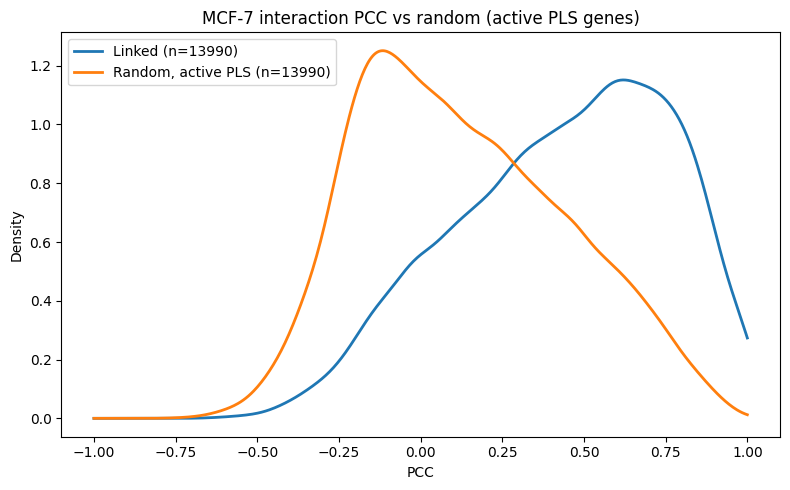

In [45]:
PLSgene = pd.read_csv("../GRCh38-Closest-Genes-All.tsv", sep="\t", header=None, usecols=[4, 12])
PLSgene.columns = ['cCRE_id', 'gene']
PLSgene['gene'] = PLSgene['gene'].str.split('.').str[0]
PLSgene = PLSgene.drop_duplicates().reset_index(drop=True)

mcf7_active_pls_genes = set(PLSgene[PLSgene['cCRE_id'].isin(cCRE_files['MCF-7']['P'])]['gene'])
all_genes = [g for g in mcf7_active_pls_genes if g in gene_to_rpkm]

print(f"{len(mcf7_active_pls_genes)} genes have an active PLS in MCF-7")
print(f"{len(all_genes)} of those have bru-seq expression data")

mcf7_gene_pairs = set(map(frozenset, zip(pairs['P1_gene'], pairs['P2_gene'])))

random_pccs = []
with tqdm(total=len(pccs), desc='Random (active PLS)') as pbar:
    while len(random_pccs) < len(pccs):
        g1, g2 = np.random.choice(all_genes, 2, replace=False)
        if frozenset([g1, g2]) in mcf7_gene_pairs:
            continue
        v1 = pd.Series(gene_to_rpkm[g1])
        v2 = pd.Series(gene_to_rpkm[g2])
        pcc, _ = stats.pearsonr(v1.values, v2.values)
        random_pccs.append(pcc)
        pbar.update(1)

x = np.linspace(-1, 1, 500)
fig, ax = plt.subplots(figsize=(8, 5))
for pccs_data, label in [
    (pccs,        f'Linked (n={len(pccs)})'),
    (random_pccs, f'Random, active PLS (n={len(random_pccs)})'),
]:
    kde = gaussian_kde(pd.Series(pccs_data).dropna())
    ax.plot(x, kde(x), lw=2, label=label)
ax.set_xlabel('PCC')
ax.set_ylabel('Density')
ax.set_title('MCF-7 interaction PCC vs random (active PLS genes)')
ax.legend()
plt.tight_layout()
plt.show()

In [65]:
## Function to do this per cell line
def plot_pcc_vs_random_active_pls(cell_line):
    pairs = AllExpressionDrop[cell_line][['P1_gene', 'P2_gene']].drop_duplicates()

    linked_pccs = []
    for _, row in tqdm(pairs.iterrows(), total=len(pairs), desc=f'{cell_line} linked'):
        g1, g2 = row['P1_gene'], row['P2_gene']
        if g1 not in gene_to_rpkm or g2 not in gene_to_rpkm:
            continue
        v1 = pd.Series(gene_to_rpkm[g1])
        v2 = pd.Series(gene_to_rpkm[g2])
        pcc, _ = stats.pearsonr(v1.values, v2.values)
        linked_pccs.append(pcc)

    active_pls_genes = set(PLSgene[PLSgene['cCRE_id'].isin(cCRE_files[cell_line]['P'])]['gene'])
    all_genes = [g for g in active_pls_genes if g in gene_to_rpkm]
    print(f"{len(active_pls_genes)} genes have an active PLS in {cell_line}")
    print(f"{len(all_genes)} of those have bru-seq expression data")

    gene_pairs = set(map(frozenset, zip(pairs['P1_gene'], pairs['P2_gene'])))
    random_pccs = []
    with tqdm(total=len(linked_pccs), desc='Random (active PLS)') as pbar:
        while len(random_pccs) < len(linked_pccs):
            g1, g2 = np.random.choice(all_genes, 2, replace=False)
            if frozenset([g1, g2]) in gene_pairs:
                continue
            v1 = pd.Series(gene_to_rpkm[g1])
            v2 = pd.Series(gene_to_rpkm[g2])
            pcc, _ = stats.pearsonr(v1.values, v2.values)
            random_pccs.append(pcc)
            pbar.update(1)
            
    linked_pcc_median = np.nanmedian(linked_pccs)
    random_active_pls_pcc_median = np.nanmedian(random_pccs)

    print(f"{cell_line} Linked PCC Median: {linked_pcc_median}")
    print(f"{cell_line} Random Active PLS Median: {random_active_pls_pcc_median}")

    linked_clean = [x for x in linked_pccs if not np.isnan(x)]
    random_clean = [x for x in random_pccs if not np.isnan(x)]
    stat, p_value = stats.ranksums(linked_clean, random_clean)
    print(f"{cell_line} Wilcoxon: stat={stat:.4f}, p={p_value}")
    print(f"stat={stat}, p={p_value!r}")
    with open(f'{cell_line}_wilcoxon_result.txt', 'w') as f:
        f.write(f"stat={stat}\np={p_value}\n")
    
    pcc_df = pd.DataFrame({
    'linked': linked_pccs,
    'random_active_pls': random_pccs})
    pcc_df.to_csv(f'{cell_line}_pccs.tsv', sep="\t", index=False)

    x = np.linspace(-1, 1, 500)
    fig, ax = plt.subplots(figsize=(8, 5))
    for pccs_data, label in [
        (linked_pccs,  f'Linked (n={len(linked_pccs)})'),
        (random_pccs,  f'Random, active PLS (n={len(random_pccs)})'),]:
        kde = gaussian_kde(pd.Series(pccs_data).dropna())
        ax.plot(x, kde(x), lw=2, label=label)
    ax.set_xlabel('PCC')
    ax.set_ylabel('Density')
    ax.set_title(f'{cell_line} interaction PCC vs random (active PLS genes)')
    ax.legend()
    plt.tight_layout()
    plt.savefig(f'{cell_line}_linked_vs_random_active_PLS.pdf', dpi=300)
    plt.show()

/tmp/ipykernel_1299073/3571454863.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                   | 1102/15678 [00:00<00:07, 1843.63it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Caco-2 linked: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15678/15678 [00:09<00:00, 1739.90it/s]


15317 genes have an active PLS in Caco-2
14639 of those have bru-seq expression data


/tmp/ipykernel_1299073/3571454863.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                      | 56/15678 [00:00<00:56, 276.47it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Random (active PLS): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15678/15678 [00:55<00:00, 283.27it/s]


Caco-2 Linked PCC Median: 0.459670563279997
Caco-2 Random Active PLS Median: 0.10786953609911934
Caco-2 Wilcoxon: stat=69.6825, p=0.0
stat=69.68247002773857, p=np.float64(0.0)


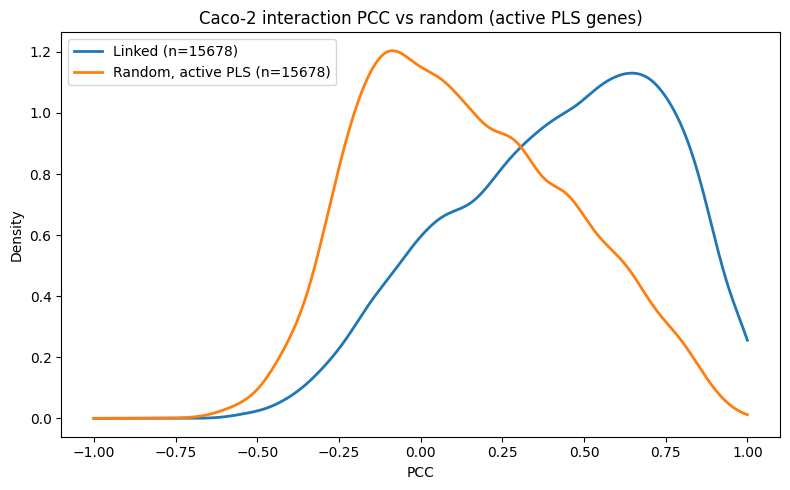

In [63]:
plot_pcc_vs_random_active_pls('Caco-2')

/tmp/ipykernel_1299073/1835495738.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                     | 865/8738 [00:00<00:04, 1726.97it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
HCT116 linked: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8738/8738 [00:04<00:00, 1829.90it/s]


15394 genes have an active PLS in HCT116
14678 of those have bru-seq expression data


/tmp/ipykernel_1299073/1835495738.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                      | 840/8738 [00:02<00:27, 284.62it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Random (active PLS): 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8738/8738 [00:30<00:00, 284.83it/s]


HCT116 Linked PCC Median: 0.47167594557852677
HCT116 Random Active PLS Median: 0.1116708002093833
HCT116 Wilcoxon: stat=52.9634, p=0.0
stat=52.96343437953536, p=np.float64(0.0)


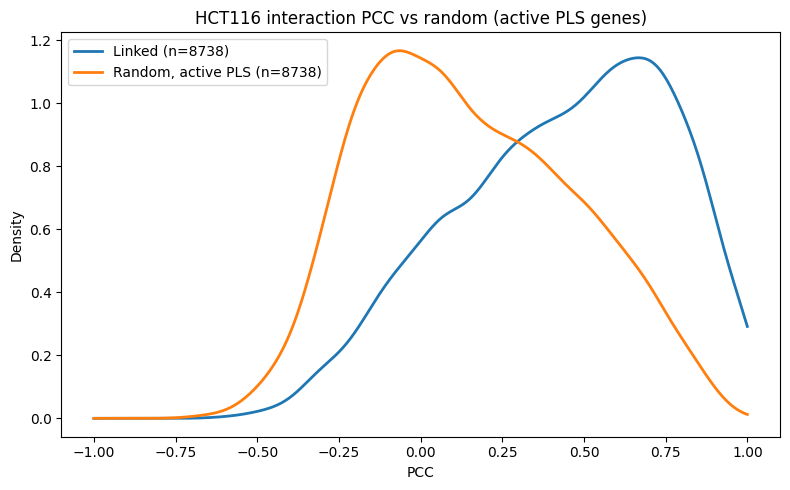

In [66]:
plot_pcc_vs_random_active_pls('HCT116')

/tmp/ipykernel_1299073/1835495738.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                    | 182/19027 [00:00<00:10, 1817.06it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
HepG2 linked: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 19027/19027 [00:10<00:00, 1735.18it/s]


14632 genes have an active PLS in HepG2
13970 of those have bru-seq expression data


/tmp/ipykernel_1299073/1835495738.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                      | 60/19027 [00:00<01:03, 296.65it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Random (active PLS): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 19027/19027 [01:03<00:00, 298.01it/s]


HepG2 Linked PCC Median: 0.4501578188238848
HepG2 Random Active PLS Median: 0.13310205495800329
HepG2 Wilcoxon: stat=69.8923, p=0.0
stat=69.89225035301486, p=np.float64(0.0)


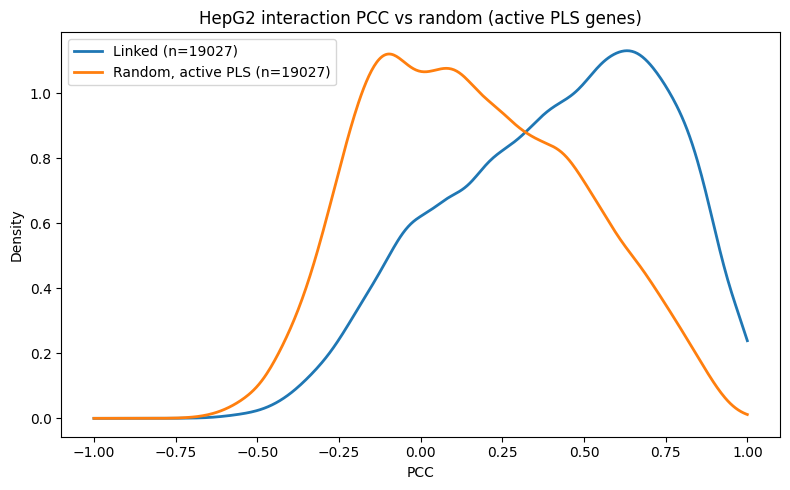

In [67]:
plot_pcc_vs_random_active_pls('HepG2')

/tmp/ipykernel_1299073/1835495738.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                     | 354/8983 [00:00<00:04, 1769.66it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
K562 linked: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8983/8983 [00:05<00:00, 1765.25it/s]


15626 genes have an active PLS in K562
14872 of those have bru-seq expression data


/tmp/ipykernel_1299073/1835495738.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                      | 261/8983 [00:00<00:30, 286.42it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Random (active PLS): 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8983/8983 [00:31<00:00, 285.23it/s]


K562 Linked PCC Median: 0.5190557072169842
K562 Random Active PLS Median: 0.17052723150271917
K562 Wilcoxon: stat=55.1998, p=0.0
stat=55.19980550254522, p=np.float64(0.0)


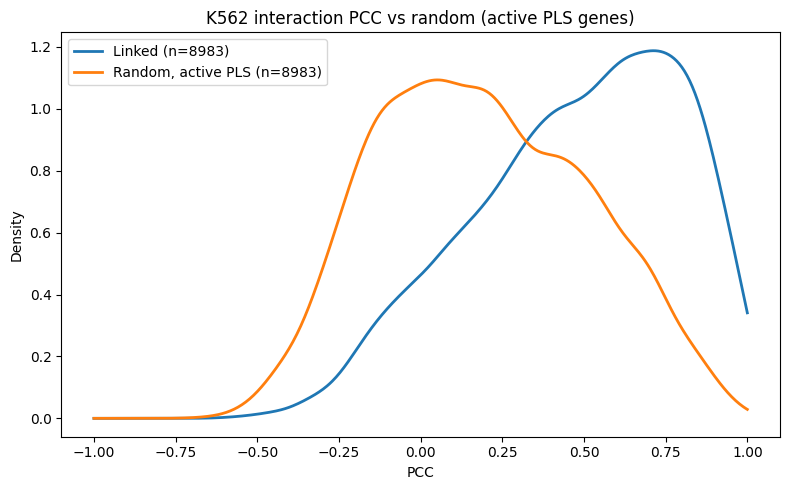

In [68]:
plot_pcc_vs_random_active_pls('K562')

/tmp/ipykernel_1299073/1835495738.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                   | 1244/21825 [00:00<00:11, 1764.82it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
MCF linked: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21825/21825 [00:12<00:00, 1758.16it/s]


14265 genes have an active PLS in MCF
13605 of those have bru-seq expression data


/tmp/ipykernel_1299073/1835495738.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                      | 31/21825 [00:00<01:11, 303.57it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Random (active PLS): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21825/21825 [01:11<00:00, 303.49it/s]


MCF Linked PCC Median: 0.4642918754708157
MCF Random Active PLS Median: 0.13341122548678194
MCF Wilcoxon: stat=78.5366, p=0.0
stat=78.53655954944752, p=np.float64(0.0)


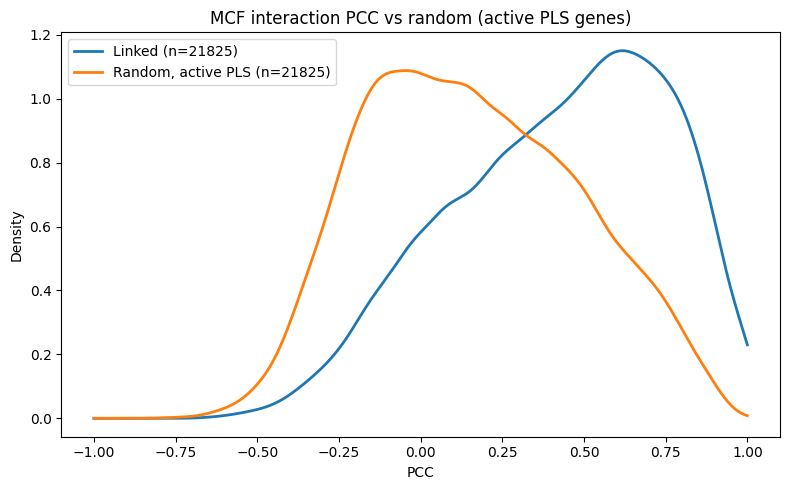

In [69]:
plot_pcc_vs_random_active_pls('MCF')

/tmp/ipykernel_1299073/2195043663.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                   | 1323/13990 [00:00<00:06, 1889.02it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
MCF-7 linked: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 13990/13990 [00:07<00:00, 1886.68it/s]


16370 genes have an active PLS in MCF-7
15638 of those have bru-seq expression data


/tmp/ipykernel_1299073/2195043663.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.                                     | 465/13990 [00:01<00:47, 285.20it/s]
  pcc, _ = stats.pearsonr(v1.values, v2.values)
Random (active PLS): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 13990/13990 [00:49<00:00, 284.71it/s]


MCF-7 Linked PCC Median: 0.47416323183553855
MCF-7 Random Active PLS Median: 0.08697833332533289


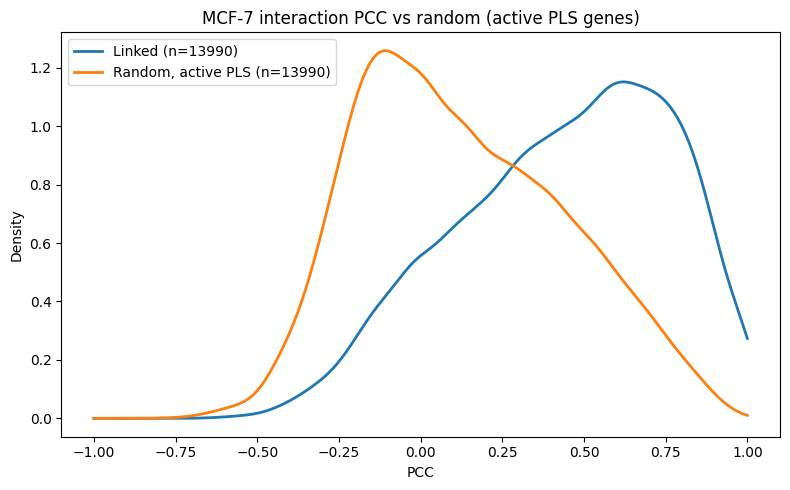

In [24]:
plot_pcc_vs_random_active_pls('MCF-7')

In [ ]:
## Get median PCC of active PLS and Linked

In [15]:
def get_median(cell_line):
    pairs = AllExpressionDrop[cell_line][['P1_gene', 'P2_gene']].drop_duplicates()

    linked_pccs = []
    for _, row in tqdm(pairs.iterrows(), total=len(pairs), desc=f'{cell_line} linked'):
        g1, g2 = row['P1_gene'], row['P2_gene']
        if g1 not in gene_to_rpkm or g2 not in gene_to_rpkm:
            continue
        v1 = pd.Series(gene_to_rpkm[g1])
        v2 = pd.Series(gene_to_rpkm[g2])
        pcc, _ = stats.pearsonr(v1.values, v2.values)
        linked_pccs.append(pcc)

    active_pls_genes = set(PLSgene[PLSgene['cCRE_id'].isin(cCRE_files[cell_line]['P'])]['gene'])
    all_genes = [g for g in active_pls_genes if g in gene_to_rpkm]
    print(f"{len(active_pls_genes)} genes have an active PLS in {cell_line}")
    print(f"{len(all_genes)} of those have bru-seq expression data")

    gene_pairs = set(map(frozenset, zip(pairs['P1_gene'], pairs['P2_gene'])))
    random_pccs = []
    with tqdm(total=len(linked_pccs), desc='Random (active PLS)') as pbar:
        while len(random_pccs) < len(linked_pccs):
            g1, g2 = np.random.choice(all_genes, 2, replace=False)
            if frozenset([g1, g2]) in gene_pairs:
                continue
            v1 = pd.Series(gene_to_rpkm[g1])
            v2 = pd.Series(gene_to_rpkm[g2])
            pcc, _ = stats.pearsonr(v1.values, v2.values)
            random_pccs.append(pcc)
            pbar.update(1)
            
    linked_pcc_median = np.nanmedian(linked_pccs)
    random_active_pls_pcc_median = np.nanmedian(random_pccs)

    print(f"{cell_line} Linked PCC Median: {linked_pcc_median}")
    print(f"{cell_line} Random Active PLS Median: {random_active_pls_pcc_median}")

In [ ]:
get_median('Caco-2')

In [ ]:
## Wilcoxon signed-rank test
linked = [0.459670563279997, 0.47167594557852677, 0.4501578188238848, 0.5190557072169842, 0.4642918754708157, 0.459670563279997]
random_active = [0.11611735786382821, 0.11469312826445369, 0.1300743085909597, 0.16252375099685568, 0.13277416307197382, 0.1128195840082318]

stats.wilcoxon(linked, random_active)

In [25]:
stats = pd.read_csv("Median-PCCs.tsv", sep = "\t", header = 0)
stats.head()

,Cell-Line,Linked-PCC,Random-PCC
0,Caco-2,0.459671,0.108415
1,HCT116,0.471676,0.122836
2,HepG2,0.450158,0.125850
3,K562,0.519056,0.165156
4,MCF-10A,0.464292,0.131660


In [26]:
linked = stats['Linked-PCC']
random_active = stats['Random-PCC']

In [27]:
stats.wilcoxon(linked, random_active)

AttributeError: 'DataFrame' object has no attribute 'wilcoxon'

In [28]:
from scipy import stats as scipy_stats

scipy_stats.wilcoxon(linked, random_active)

WilcoxonResult(statistic=np.float64(0.0), pvalue=np.float64(0.03125))

In [29]:
result = scipy_stats.wilcoxon(linked, random_active)

with open("wilcoxon_result.txt", "w") as f:
    f.write(f"Statistic: {result.statistic}\n")
    f.write(f"P-value: {result.pvalue}\n")